In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("taxis.csv")
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,23-03-2019 20:21,23-03-2019 20:27,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,04-03-2019 16:11,04-03-2019 16:19,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,27-03-2019 17:53,27-03-2019 18:00,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,10-03-2019 01:23,10-03-2019 01:49,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,30-03-2019 13:27,30-03-2019 13:37,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [3]:
df.shape

(6433, 14)

In [4]:
df.columns

Index(['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls',
       'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone',
       'pickup_borough', 'dropoff_borough'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pickup           6433 non-null   object 
 1   dropoff          6433 non-null   object 
 2   passengers       6433 non-null   int64  
 3   distance         6433 non-null   float64
 4   fare             6433 non-null   float64
 5   tip              6433 non-null   float64
 6   tolls            6433 non-null   float64
 7   total            6433 non-null   float64
 8   color            6433 non-null   object 
 9   payment          6389 non-null   object 
 10  pickup_zone      6407 non-null   object 
 11  dropoff_zone     6388 non-null   object 
 12  pickup_borough   6407 non-null   object 
 13  dropoff_borough  6388 non-null   object 
dtypes: float64(5), int64(1), object(8)
memory usage: 703.7+ KB


In [6]:
null = df.isnull().sum()
null[null>0]

payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [7]:
df.describe()

,passengers,distance,fare,tip,tolls,total
count,6433.000000,6433.000000,6433.000000,6433.00000,6433.000000,6433.000000
mean,1.539251,3.024617,13.091073,1.97922,0.325273,18.517794
std,1.203768,3.827867,11.551804,2.44856,1.415267,13.815570
min,0.000000,0.000000,1.000000,0.00000,0.000000,1.300000
25%,1.000000,0.980000,6.500000,0.00000,0.000000,10.800000
50%,1.000000,1.640000,9.500000,1.70000,0.000000,14.160000
75%,2.000000,3.210000,15.000000,2.80000,0.000000,20.300000
max,6.000000,36.700000,150.000000,33.20000,24.020000,174.820000


In [8]:
df.select_dtypes("number").skew()

passengers    2.359143
distance      3.008206
fare          3.217463
tip           2.665152
tolls         5.074936
total         3.093333
dtype: float64

In [9]:
df["color"].unique()

array(['yellow', 'green'], dtype=object)

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
len(df["pickup_zone"].unique())

195

In [12]:
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,23-03-2019 20:21,23-03-2019 20:27,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,04-03-2019 16:11,04-03-2019 16:19,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,27-03-2019 17:53,27-03-2019 18:00,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,10-03-2019 01:23,10-03-2019 01:49,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,30-03-2019 13:27,30-03-2019 13:37,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [13]:
date = df["pickup"][3]
str(date.split(" ")[1]).split(":")[0]

'01'

In [14]:
def timemin(date:str):
    return int(str(date.split(" ")[1]).split(":")[1])
def timehr(date:str):
    return int(str(date.split(" ")[1]).split(":")[0])

In [15]:
df.insert(0,"pickup_hr",df["pickup"].apply(timehr))
df.insert(1,"pickup_min",df["pickup"].apply(timemin))
df.insert(2,"dropoff_hr",df["dropoff"].apply(timehr))
df.insert(3,"dropoff_min",df["dropoff"].apply(timemin))

In [16]:
# df["pickup_hr"] = df["pickup"].apply(timehr)
# df["pickup_min"] = df["pickup"].apply(timemin)

# df["dropoff_hr"] = df["dropoff"].apply(timehr)
# df["dropoff_min"] = df["dropoff"].apply(timemin)

df.drop(["pickup","dropoff","pickup_zone","dropoff_zone"],axis=1,inplace=True)
df.head()

,pickup_hr,pickup_min,dropoff_hr,dropoff_min,passengers,distance,fare,tip,tolls,total,color,payment,pickup_borough,dropoff_borough
0,20,21,20,27,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Manhattan,Manhattan
1,16,11,16,19,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Manhattan,Manhattan
2,17,53,18,0,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Manhattan,Manhattan
3,1,23,1,49,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Manhattan,Manhattan
4,13,27,13,37,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Manhattan,Manhattan


In [17]:
df["pickup_borough"].unique()

array(['Manhattan', 'Queens', nan, 'Bronx', 'Brooklyn'], dtype=object)

In [18]:
num_cols = df.select_dtypes("number").columns.tolist()
cat_cols = df.select_dtypes("object").columns.tolist()

num_cols.pop(-1)

print(num_cols)
print(cat_cols)

['pickup_hr', 'pickup_min', 'dropoff_hr', 'dropoff_min', 'passengers', 'distance', 'fare', 'tip', 'tolls']
['color', 'payment', 'pickup_borough', 'dropoff_borough']


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pickup_hr        6433 non-null   int64  
 1   pickup_min       6433 non-null   int64  
 2   dropoff_hr       6433 non-null   int64  
 3   dropoff_min      6433 non-null   int64  
 4   passengers       6433 non-null   int64  
 5   distance         6433 non-null   float64
 6   fare             6433 non-null   float64
 7   tip              6433 non-null   float64
 8   tolls            6433 non-null   float64
 9   total            6433 non-null   float64
 10  color            6433 non-null   object 
 11  payment          6389 non-null   object 
 12  pickup_borough   6407 non-null   object 
 13  dropoff_borough  6388 non-null   object 
dtypes: float64(5), int64(5), object(4)
memory usage: 703.7+ KB


In [19]:
SDF = SDF

NameError: name 'SDF' is not defined

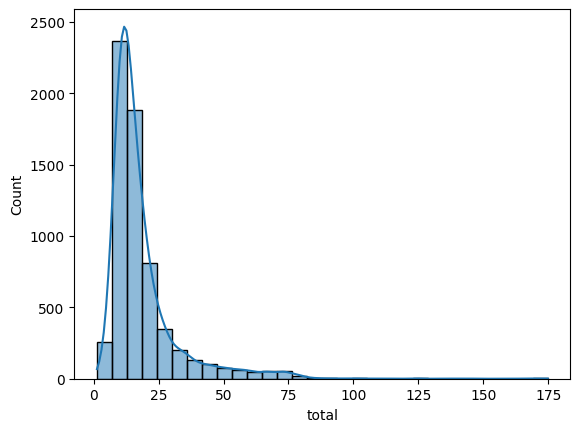

In [ ]:
sns.histplot(df,x="total",bins=30,kde=True)
plt.show()

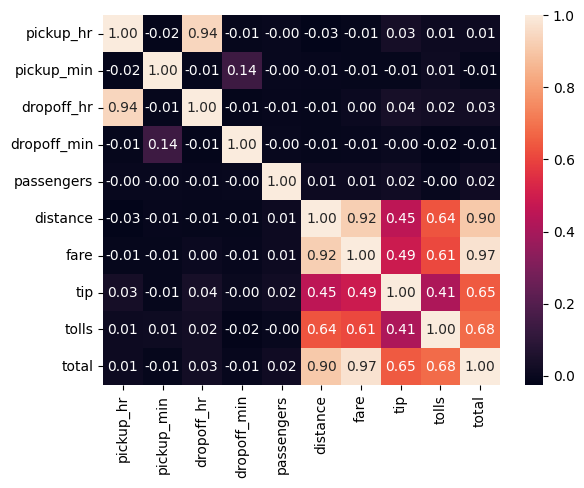

In [ ]:
sns.heatmap(df.corr(numeric_only=True),annot=True,fmt=".2f")
plt.show()

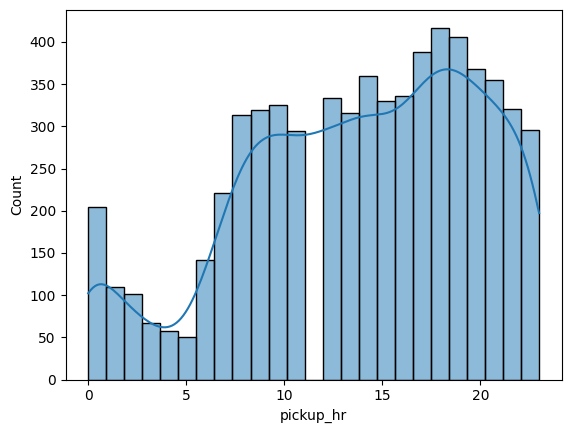

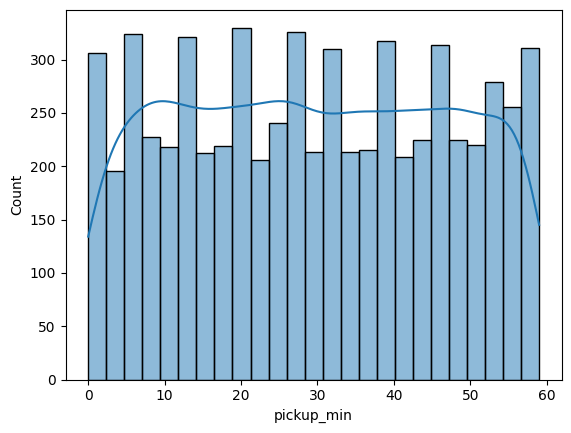

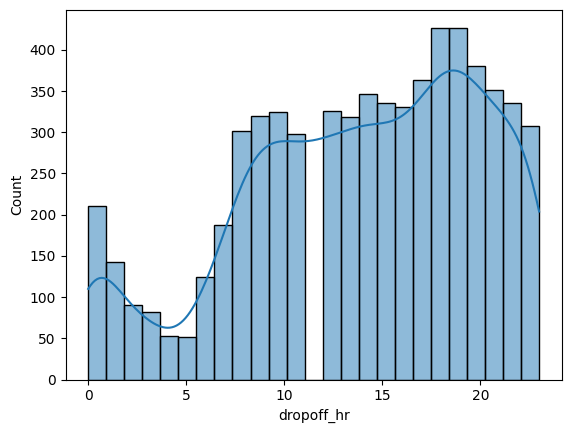

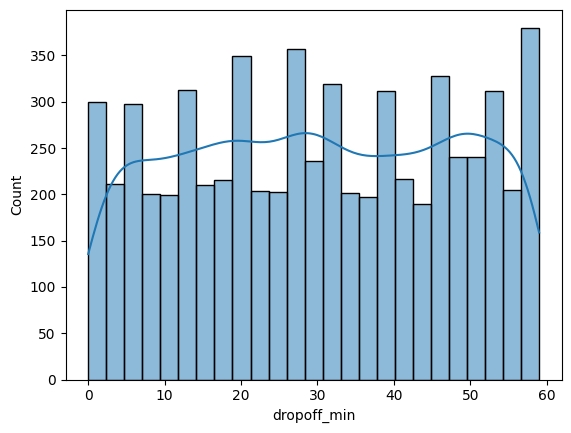

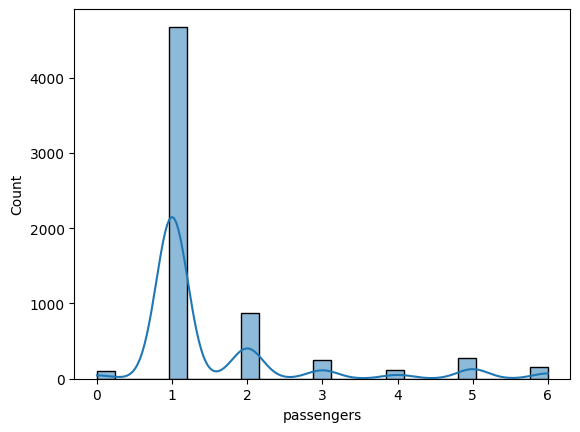

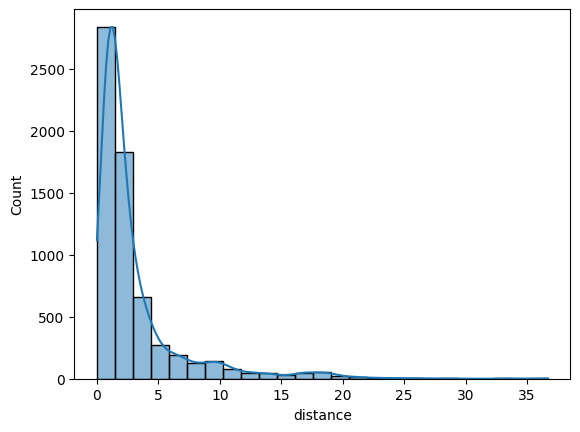

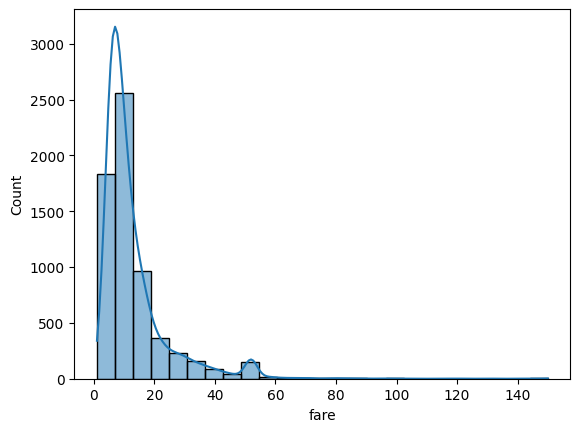

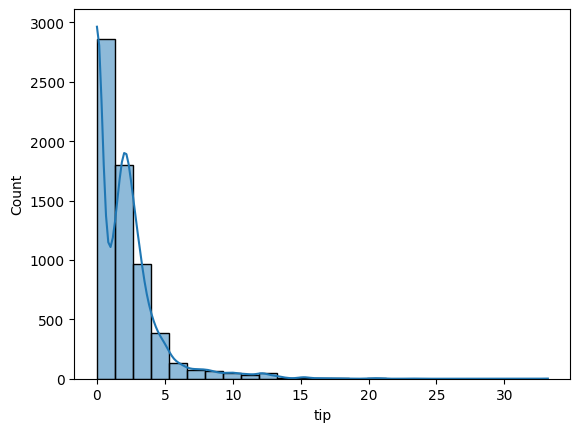

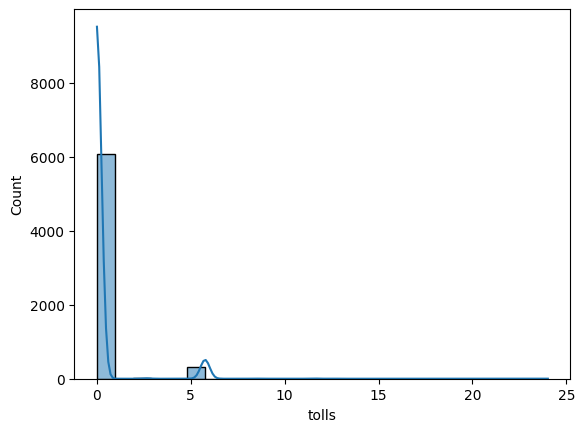

In [ ]:
for i in num_cols:
    sns.histplot(df,x=i,bins=25,kde=True)
    plt.show()

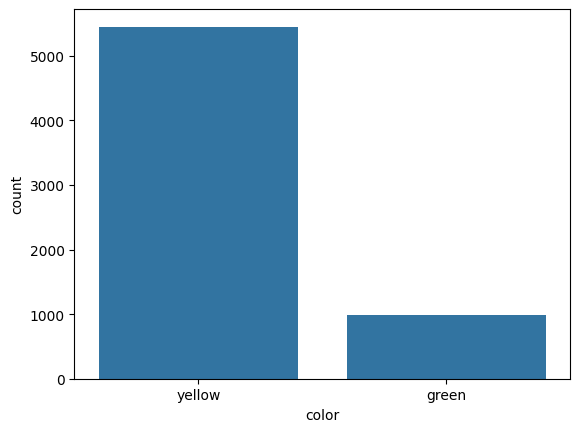

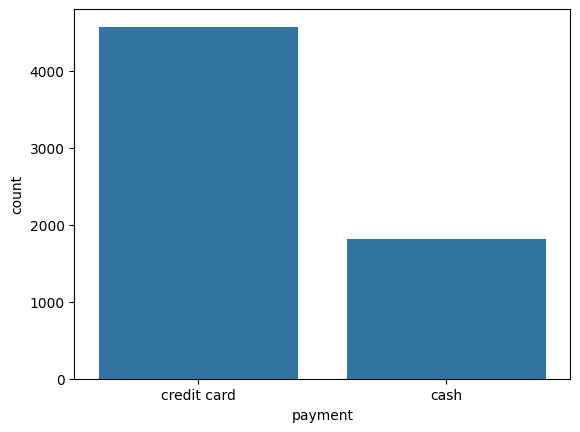

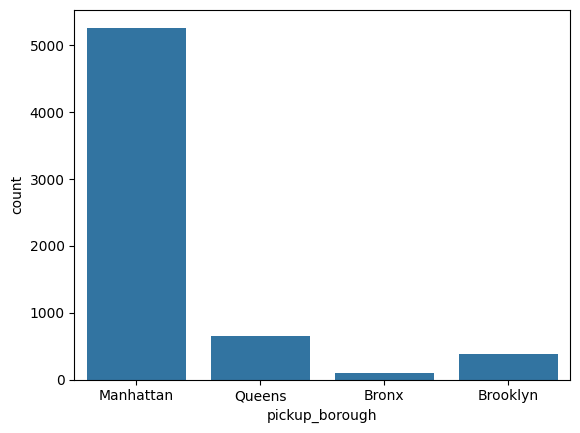

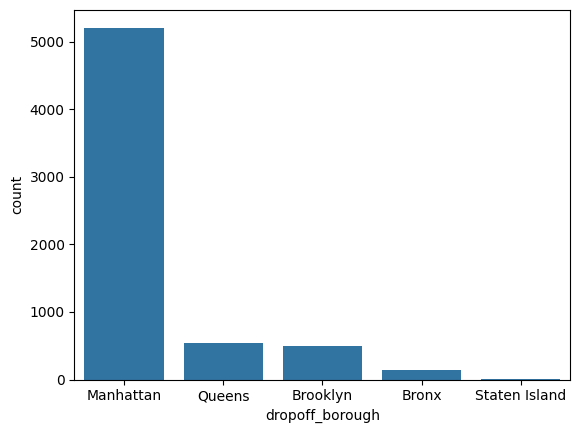

In [ ]:
for i in cat_cols:
    sns.countplot(df,x=i)
    plt.show()

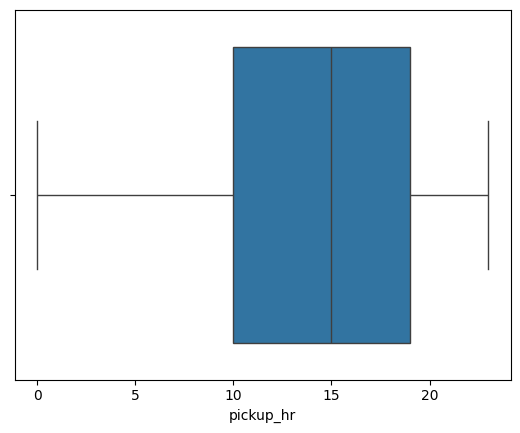

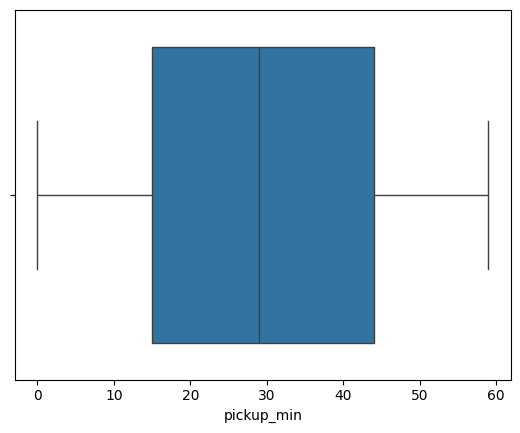

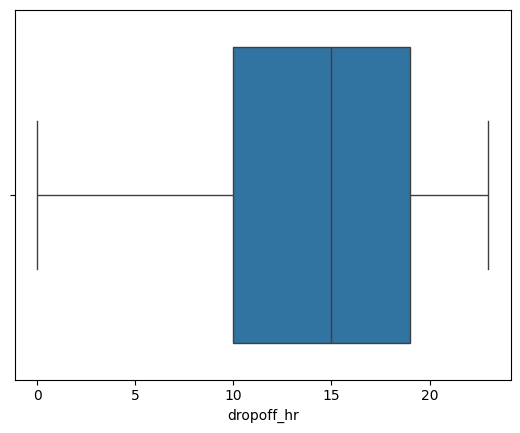

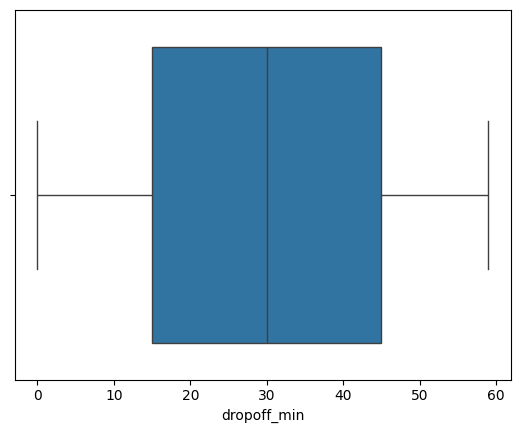

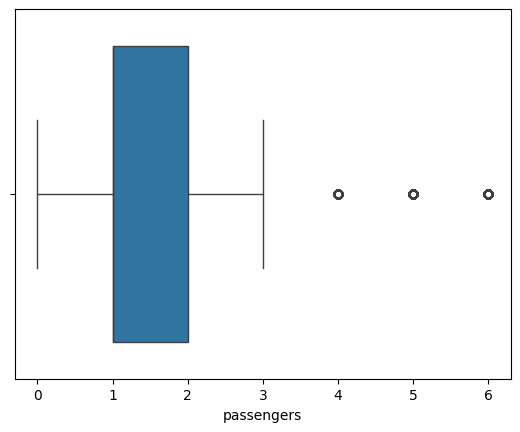

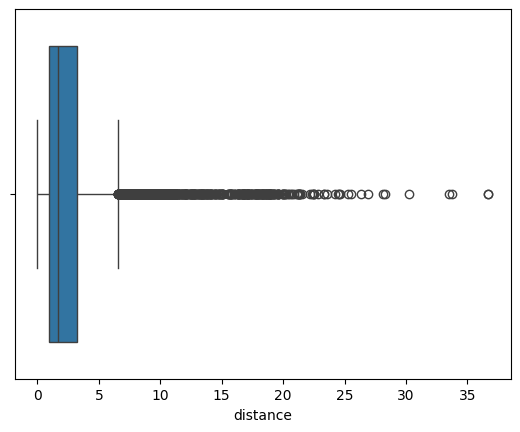

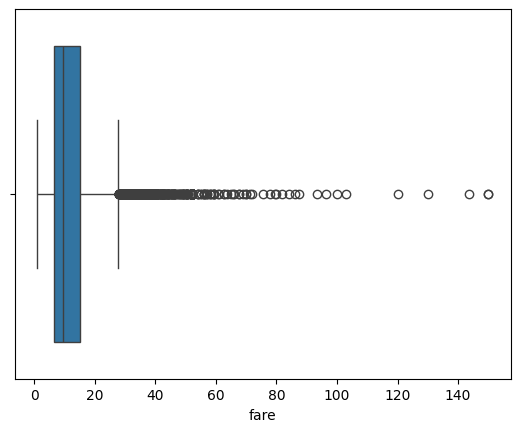

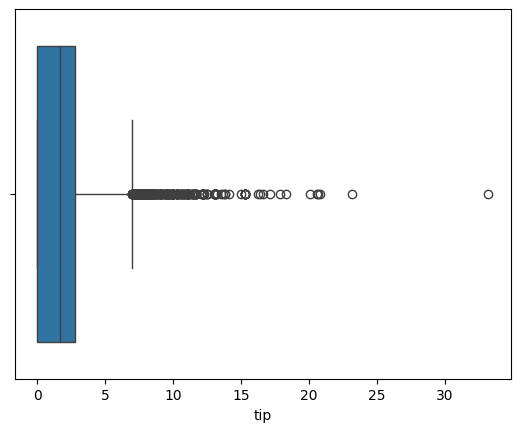

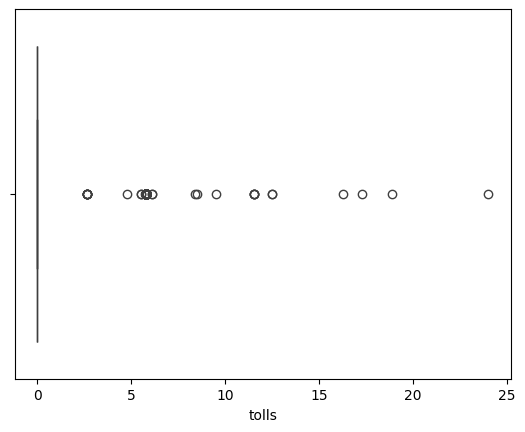

In [ ]:
for i in num_cols:
    sns.boxplot(df,x=i)
    plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop("total",axis=1)
y = df["total"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [ ]:
from sklearn.preprocessing import StandardScaler,OneHotEncoder,PowerTransformer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

In [ ]:
preporcessor = ColumnTransformer([
    ("num",Pipeline([
        ("impute",SimpleImputer(strategy="median")),
        ("skew",PowerTransformer(method="yeo-johnson")),
        ("scaler",StandardScaler())
    ]),num_cols),
    ("cat",Pipeline([
        ("impute",SimpleImputer(strategy="most_frequent")),
        ("encode",OneHotEncoder(handle_unknown="ignore"))
    ]),cat_cols)
])

preporcessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

In [ ]:
X.head()

,pickup_hr,pickup_min,dropoff_hr,dropoff_min,passengers,distance,fare,tip,tolls,color,payment,pickup_borough,dropoff_borough
0,20,21,20,27,1,1.60,7.0,2.15,0.0,yellow,credit card,Manhattan,Manhattan
1,16,11,16,19,1,0.79,5.0,0.00,0.0,yellow,cash,Manhattan,Manhattan
2,17,53,18,0,1,1.37,7.5,2.36,0.0,yellow,credit card,Manhattan,Manhattan
3,1,23,1,49,1,7.70,27.0,6.15,0.0,yellow,credit card,Manhattan,Manhattan
4,13,27,13,37,3,2.16,9.0,1.10,0.0,yellow,credit card,Manhattan,Manhattan


In [ ]:
for i in cat_cols:
    print(df[i].unique())

['yellow' 'green']
['credit card' 'cash' nan]
['Manhattan' 'Queens' nan 'Bronx' 'Brooklyn']
['Manhattan' 'Queens' 'Brooklyn' nan 'Bronx' 'Staten Island']


In [ ]:
X_train_pre = preporcessor.fit_transform(X_train)
X_test_pre = preporcessor.transform(X_test)

In [ ]:
from sklearn.metrics import r2_score,mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor

In [ ]:
models = {
    "LR":LinearRegression(),
    "KNN":KNeighborsRegressor(n_neighbors=5,weights="distance"),
    "DT": DecisionTreeRegressor(),
    "XG":XGBRegressor(),
    "GB":GradientBoostingRegressor()
}

In [ ]:
for i , model in models.items():
    model.fit(X_train_pre,y_train)
    y_pred = model.predict(X_test_pre)
    n = X_test_pre.shape[0] 
    p = X_test_pre.shape[1]
    r2 = r2_score(y_test,y_pred)
    r2_Ad = 1-((1-r2)*(n-1))/(n-p-1) 
    print(f"model : {i}") 
    print(f"r2_Ad : {r2_Ad}")
    print(f"r2    : {r2}")

model : LR
r2_Ad : 0.8054775551784101
r2    : 0.8088053108440982
model : KNN
r2_Ad : 0.8816633348468064
r2    : 0.8836877568012156
model : DT
r2_Ad : 0.9825757750251646
r2    : 0.9828738566343764
model : XG
r2_Ad : 0.9908789842725365
r2    : 0.99103502031142
model : GB
r2_Ad : 0.9935608401655813
r2    : 0.9936709968657036


In [ ]:
model_pipeline = Pipeline([
    ("preporcessor",preporcessor),
    ("model",models["DT"])
])

model_pipeline.fit(X_train,y_train)
y_pred = model_pipeline.predict(X_test)
n = X_test.shape[0] 
p = X_test.shape[1]
r2 = r2_score(y_test,y_pred)
r2_Ad = 1-((1-r2)*(n-1))/(n-p-1) 
print("model  : DT") 
print(f"r2_Ad  : {r2_Ad}")
print(f"r2     : {r2}")

model  : DT
r2_Ad  : 0.9778780667399364
r2     : 0.9781016943700925


In [ ]:
from joblib import dump

dump(model_pipeline,"model_pipeline.pkl")
dump(preporcessor,"preporcessor.pkl")

['preporcessor.pkl']